# Auditoria de Calçadas — Treinamento de detector YOLOv8n

Este notebook documenta o pipeline experimental de detecção de elementos urbanos para apoiar uma auditoria visual de calçadas: obtenção e inspeção do dataset, preparação dos rótulos, divisão dos dados, treinamento, avaliação e exportação do modelo para uso em uma aplicação mobile.

> **Escopo:** este é um protótipo acadêmico. O modelo detecta somente as seis classes treinadas e não realiza uma avaliação completa de acessibilidade ou conformidade de calçadas.

## Etapas
1. Preparar o ambiente.
2. Baixar e inspecionar o dataset.
3. Preparar os conjuntos de treino, validação e teste.
4. Treinar o YOLOv8n.
5. Avaliar o modelo no conjunto de teste.
6. Exportar o modelo ONNX e reunir os artefatos.

## 1. Preparação do ambiente

O notebook foi desenvolvido para execução no Google Colab com GPU. A instalação abaixo prepara as bibliotecas utilizadas nas etapas de processamento, treinamento e exportação.

In [1]:
!pip -q install ultralytics pyyaml requests
import os
import random
import shutil
import zipfile
from pathlib import Path
from collections import Counter

import requests
import yaml
import torch
from ultralytics import YOLO

SEED = 42
random.seed(SEED)

print("GPU disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU disponível: True
GPU: Tesla T4


## 2. Download do dataset

Dataset usado: Zenodo. O arquivo é baixado apenas se ainda não existir na sessão do Colab e, em seguida, extraído para `/content/dataset_urbano`.

**Fonte:** [Dataset no Zenodo](https://zenodo.org/records/18871460)


In [2]:
url = "https://zenodo.org/records/18871460/files/Data_sets.zip?download=1"
zip_path = Path("/content/dataset_urbano.zip")
destino = Path("/content/dataset_urbano")
base_dataset = destino / "Data_sets"

if not zip_path.exists():
    with requests.get(url, stream=True, timeout=120) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))
        baixado = 0

        with zip_path.open("wb") as arquivo:
            for bloco in response.iter_content(chunk_size=1024 * 1024):
                if bloco:
                    arquivo.write(bloco)
                    baixado += len(bloco)
                    if total:
                        print(f"\rDownload: {baixado / total:.1%}", end="")

    print("\nDownload concluído.")
else:
    print("Arquivo ZIP já existe; download ignorado.")

destino.mkdir(parents=True, exist_ok=True)
if not base_dataset.exists():
    with zipfile.ZipFile(zip_path, "r") as arquivo_zip:
        arquivo_zip.extractall(destino)

if not base_dataset.exists():
    raise FileNotFoundError(f"Não encontrei a pasta esperada: {base_dataset}")

print("Pastas do dataset:", sorted(p.name for p in base_dataset.iterdir() if p.is_dir()))

Download: 100.0%
Download concluído.
Pastas do dataset: ['animal', 'cracks', 'good_road', 'open_manhole', 'pothole', 'traffic_lights', 'waste_container']


## 3. Inspeção das imagens e anotações

As anotações seguem o formato YOLO: `id_classe x_centro y_centro largura altura`, com coordenadas normalizadas entre 0 e 1. As células seguintes resumem a quantidade de imagens, a correspondência entre imagens e rótulos e possíveis problemas de formatação.

In [3]:
import os
from collections import Counter

base = "/content/dataset_urbano/Data_sets"

for classe in sorted(os.listdir(base)):
    pasta = os.path.join(base, classe)
    if not os.path.isdir(pasta):
        continue

    imagens = [
        f for f in os.listdir(os.path.join(pasta, "images"))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    rotulos = [
        f for f in os.listdir(os.path.join(pasta, "labels"))
        if f.endswith(".txt")
    ]

    print(f"{classe}: {len(imagens)} imagens | {len(rotulos)} arquivos de rótulos")

    if rotulos:
        arquivo = os.path.join(pasta, "labels", rotulos[0])
        with open(arquivo, "r") as f:
            print("  Exemplo de rótulo:", f.readline().strip())

animal: 600 imagens | 600 arquivos de rótulos
  Exemplo de rótulo: 0 0.348750 0.462512 0.103750 0.124649
cracks: 166 imagens | 166 arquivos de rótulos
  Exemplo de rótulo: 4 0.465608 0.605820 0.783069 0.671958
good_road: 100 imagens | 100 arquivos de rótulos
  Exemplo de rótulo: 
open_manhole: 152 imagens | 152 arquivos de rótulos
  Exemplo de rótulo: 5 0.397266 0.409392 0.288360 0.197090
pothole: 300 imagens | 300 arquivos de rótulos
  Exemplo de rótulo: 3 0.639881 0.545635 0.426587 0.546296
traffic_lights: 600 imagens | 600 arquivos de rótulos
  Exemplo de rótulo: 1 0.123750 0.358019 0.042500 0.108490
waste_container: 600 imagens | 600 arquivos de rótulos
  Exemplo de rótulo: 2 0.666562 0.481250 0.331875 0.702500


In [4]:
import os
from collections import Counter

base = "/content/dataset_urbano/Data_sets"
ids = Counter()
problemas = []
total_imagens = 0
total_caixas = 0

for classe in sorted(os.listdir(base)):
    pasta = os.path.join(base, classe)
    if not os.path.isdir(pasta):
        continue

    img_dir = os.path.join(pasta, "images")
    lbl_dir = os.path.join(pasta, "labels")

    imagens = {
        os.path.splitext(f)[0]
        for f in os.listdir(img_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    }
    rotulos = {
        os.path.splitext(f)[0]
        for f in os.listdir(lbl_dir)
        if f.endswith(".txt")
    }

    total_imagens += len(imagens)
    print(f"\n{classe}: imagens={len(imagens)}, rótulos={len(rotulos)}")
    print("  Imagens sem arquivo de rótulo:", len(imagens - rotulos))
    print("  Rótulos sem imagem:", len(rotulos - imagens))

    for nome in rotulos:
        caminho = os.path.join(lbl_dir, nome + ".txt")
        with open(caminho, "r") as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                try:
                    id_classe = int(partes[0])
                    if len(partes) != 5:
                        problemas.append((classe, nome, "quantidade de valores incorreta"))
                        continue
                    coords = list(map(float, partes[1:]))
                    ids[id_classe] += 1
                    total_caixas += 1
                except ValueError:
                    problemas.append((classe, nome, "rótulo inválido"))

print("\n=== RESUMO ===")
print("Total de imagens:", total_imagens)
print("Total de caixas anotadas:", total_caixas)
print("Quantidade de anotações por ID:", dict(sorted(ids.items())))
print("Problemas encontrados:", len(problemas))
print("Exemplos de problemas:", problemas[:10])


animal: imagens=600, rótulos=600
  Imagens sem arquivo de rótulo: 0
  Rótulos sem imagem: 0

cracks: imagens=166, rótulos=166
  Imagens sem arquivo de rótulo: 0
  Rótulos sem imagem: 0

good_road: imagens=100, rótulos=100
  Imagens sem arquivo de rótulo: 0
  Rótulos sem imagem: 0

open_manhole: imagens=152, rótulos=152
  Imagens sem arquivo de rótulo: 0
  Rótulos sem imagem: 0

pothole: imagens=300, rótulos=300
  Imagens sem arquivo de rótulo: 0
  Rótulos sem imagem: 0

traffic_lights: imagens=600, rótulos=600
  Imagens sem arquivo de rótulo: 0
  Rótulos sem imagem: 0

waste_container: imagens=600, rótulos=600
  Imagens sem arquivo de rótulo: 0
  Rótulos sem imagem: 0

=== RESUMO ===
Total de imagens: 2518
Total de caixas anotadas: 5573
Quantidade de anotações por ID: {0: 1113, 1: 2522, 2: 1112, 3: 478, 4: 194, 5: 154}
Problemas encontrados: 0
Exemplos de problemas: []


In [5]:
import os
from collections import Counter

base = "/content/dataset_urbano/Data_sets"

for classe in sorted(os.listdir(base)):
    pasta = os.path.join(base, classe, "labels")
    if not os.path.isdir(pasta):
        continue

    ids = Counter()
    vazios = 0

    for nome in os.listdir(pasta):
        if not nome.endswith(".txt"):
            continue
        with open(os.path.join(pasta, nome), "r") as f:
            linhas = [l.strip() for l in f if l.strip()]

        if not linhas:
            vazios += 1

        for linha in linhas:
            ids[linha.split()[0]] += 1

    print(f"{classe}: IDs={dict(ids)}, rótulos vazios={vazios}")

animal: IDs={'0': 1113}, rótulos vazios=0
cracks: IDs={'4': 194}, rótulos vazios=0
good_road: IDs={}, rótulos vazios=100
open_manhole: IDs={'5': 154}, rótulos vazios=0
pothole: IDs={'3': 478}, rótulos vazios=0
traffic_lights: IDs={'1': 2522}, rótulos vazios=0
waste_container: IDs={'2': 1112}, rótulos vazios=0


### Decisão sobre as classes

A pasta `good_road` foi excluída porque seus arquivos estavam vazios. O treinamento utiliza seis classes com rótulos disponíveis:

| ID | Classe original | Interpretação no projeto |
|---:|---|---|
| 0 | `animal` | elemento urbano contextual |
| 1 | `traffic_lights` | elemento de sinalização contextual |
| 2 | `waste_container` | possível obstáculo, dependendo da posição |
| 3 | `pothole` | buraco ou dano no pavimento |
| 4 | `cracks` | rachaduras no pavimento |
| 5 | `open_manhole` | bueiro aberto |


## 4. Preparação dos dados para YOLO

Os arquivos são divididos por classe em treino (80%), validação (10%) e teste (10%), usando uma seed fixa para tornar a divisão reproduzível.

In [6]:
import os, random, shutil, yaml
from pathlib import Path

random.seed(42)

origem = Path("/content/dataset_urbano/Data_sets")
destino = Path("/content/yolo_auditoria")

classes = {
    "animal": 0,
    "traffic_lights": 1,
    "waste_container": 2,
    "pothole": 3,
    "cracks": 4,
    "open_manhole": 5,
}

# Criar estrutura do YOLO
if destino.exists():
    shutil.rmtree(destino)

for split in ["train", "val", "test"]:
    (destino / "images" / split).mkdir(parents=True, exist_ok=True)
    (destino / "labels" / split).mkdir(parents=True, exist_ok=True)

resumo = {}

for classe in classes:
    pasta = origem / classe
    arquivos = [
        f for f in (pasta / "images").iterdir()
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        and (pasta / "labels" / (f.stem + ".txt")).exists()
    ]
    random.shuffle(arquivos)

    n = len(arquivos)
    n_treino = int(n * 0.8)
    n_val = int(n * 0.1)

    grupos = {
        "train": arquivos[:n_treino],
        "val": arquivos[n_treino:n_treino+n_val],
        "test": arquivos[n_treino+n_val:],
    }

    for split, lista in grupos.items():
        for img in lista:
            nome = f"{classe}_{img.stem}"
            shutil.copy2(img, destino / "images" / split / f"{nome}{img.suffix.lower()}")
            shutil.copy2(
                pasta / "labels" / f"{img.stem}.txt",
                destino / "labels" / split / f"{nome}.txt"
            )

    resumo[classe] = {s: len(v) for s, v in grupos.items()}

config = {
    "path": str(destino),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "animal",
        1: "traffic_lights",
        2: "waste_container",
        3: "pothole",
        4: "cracks",
        5: "open_manhole",
    },
}

with open(destino / "data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Dataset preparado!")
print("Divisão por classe:")
for classe, dados in resumo.items():
    print(f"{classe}: {dados}")

for split in ["train", "val", "test"]:
    print(f"{split}: {len(list((destino / 'images' / split).iterdir()))} imagens")

print("Configuração:", destino / "data.yaml")

Dataset preparado!
Divisão por classe:
animal: {'train': 480, 'val': 60, 'test': 60}
traffic_lights: {'train': 480, 'val': 60, 'test': 60}
waste_container: {'train': 480, 'val': 60, 'test': 60}
pothole: {'train': 240, 'val': 30, 'test': 30}
cracks: {'train': 132, 'val': 16, 'test': 18}
open_manhole: {'train': 121, 'val': 15, 'test': 16}
train: 1933 imagens
val: 241 imagens
test: 244 imagens
Configuração: /content/yolo_auditoria/data.yaml


## 5. Treinamento do modelo

Foi utilizado o YOLOv8n pré-treinado, com ajuste fino por 15 épocas, imagens de 640 × 640 pixels e batch size 16. A validação é utilizada durante o treinamento; o conjunto de teste fica reservado para a avaliação final.

In [7]:
from ultralytics import YOLO
import torch
import os

print("GPU disponível:", torch.cuda.is_available())

modelo = YOLO("yolov8n.pt")

resultado = modelo.train(
    data="/content/yolo_auditoria/data.yaml",
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/runs/auditoria",
    name="yolov8n",
    patience=5,
    plots=True,
    verbose=True
)

print("Treinamento concluído!")
print("Melhor modelo:", "/content/runs/auditoria/yolov8n/weights/best.pt")

GPU disponível: True
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_auditoria/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms=None, opset=N

## 6. Avaliação no conjunto de teste

A avaliação abaixo utiliza o melhor checkpoint salvo durante o treinamento e o split `test`. Além das métricas impressas, o Ultralytics salva gráficos de avaliação no diretório de resultados.

In [8]:
from ultralytics import YOLO
import os

modelo = YOLO("/content/runs/auditoria/yolov8n/weights/best.pt")

# Avaliação final no conjunto de teste
metricas = modelo.val(
    data="/content/yolo_auditoria/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/runs/auditoria",
    name="teste_final"
)

print("\n=== MÉTRICAS NO TESTE ===")
print(f"Precision: {metricas.box.mp:.4f}")
print(f"Recall:    {metricas.box.mr:.4f}")
print(f"mAP50:     {metricas.box.map50:.4f}")
print(f"mAP50-95:  {metricas.box.map:.4f}")

# Exportar o modelo para ONNX em 640x640, tamanho utilizado pelo aplicativo.
arquivo = modelo.export(format="onnx", imgsz=640)
print("\nModelo ONNX exportado:", arquivo)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3009.0±1602.5 MB/s, size: 348.5 KB)
val: Scanning /content/yolo_auditoria/labels/test... 244 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 244/244 1.9Kit/s 0.1s
val: New cache created: /content/yolo_auditoria/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.6it/s 4.4s
                   all        244        536      0.741      0.657      0.696      0.397
                animal         60         90      0.698      0.512      0.577      0.348
        traffic_lights         60        259      0.711      0.409      0.473       0.27
       waste_container         60        108        0.8      0.843      0.865      0.608
               pothole         30         42      0.774      0.762    

### 6.1 Análise das perdas e dos gráficos de avaliação

A análise das perdas ajuda a acompanhar o aprendizado do modelo ao longo das épocas. As perdas de treino e validação são verificadas a partir de `results.csv`; os gráficos de avaliação e a matriz de confusão são procurados nas pastas geradas pelo Ultralytics. Esta etapa não treina o modelo novamente.

Colunas de perda encontradas: ['train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss']


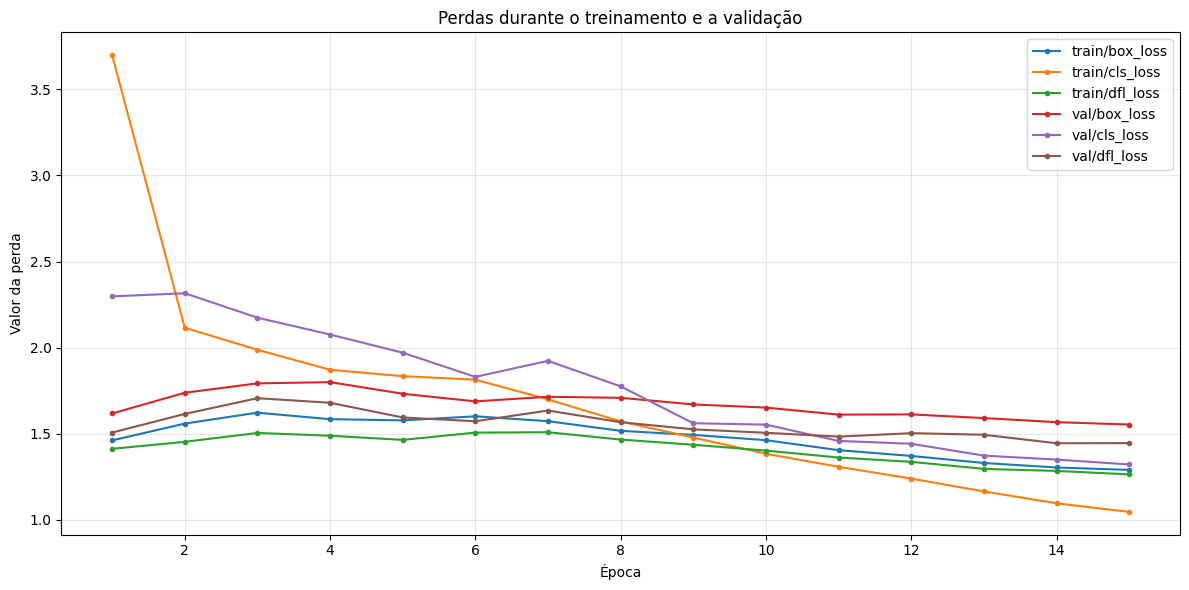

Gráfico salvo em: /content/runs/auditoria/yolov8n/curvas_perda.png

Valores de perda na última época registrada:


,epoch,train/box_loss,train/cls_loss,train/dfl_loss,val/box_loss,val/cls_loss,val/dfl_loss
14,15,1.29073,1.04696,1.26478,1.55411,1.32225,1.44629



confusion_matrix.png


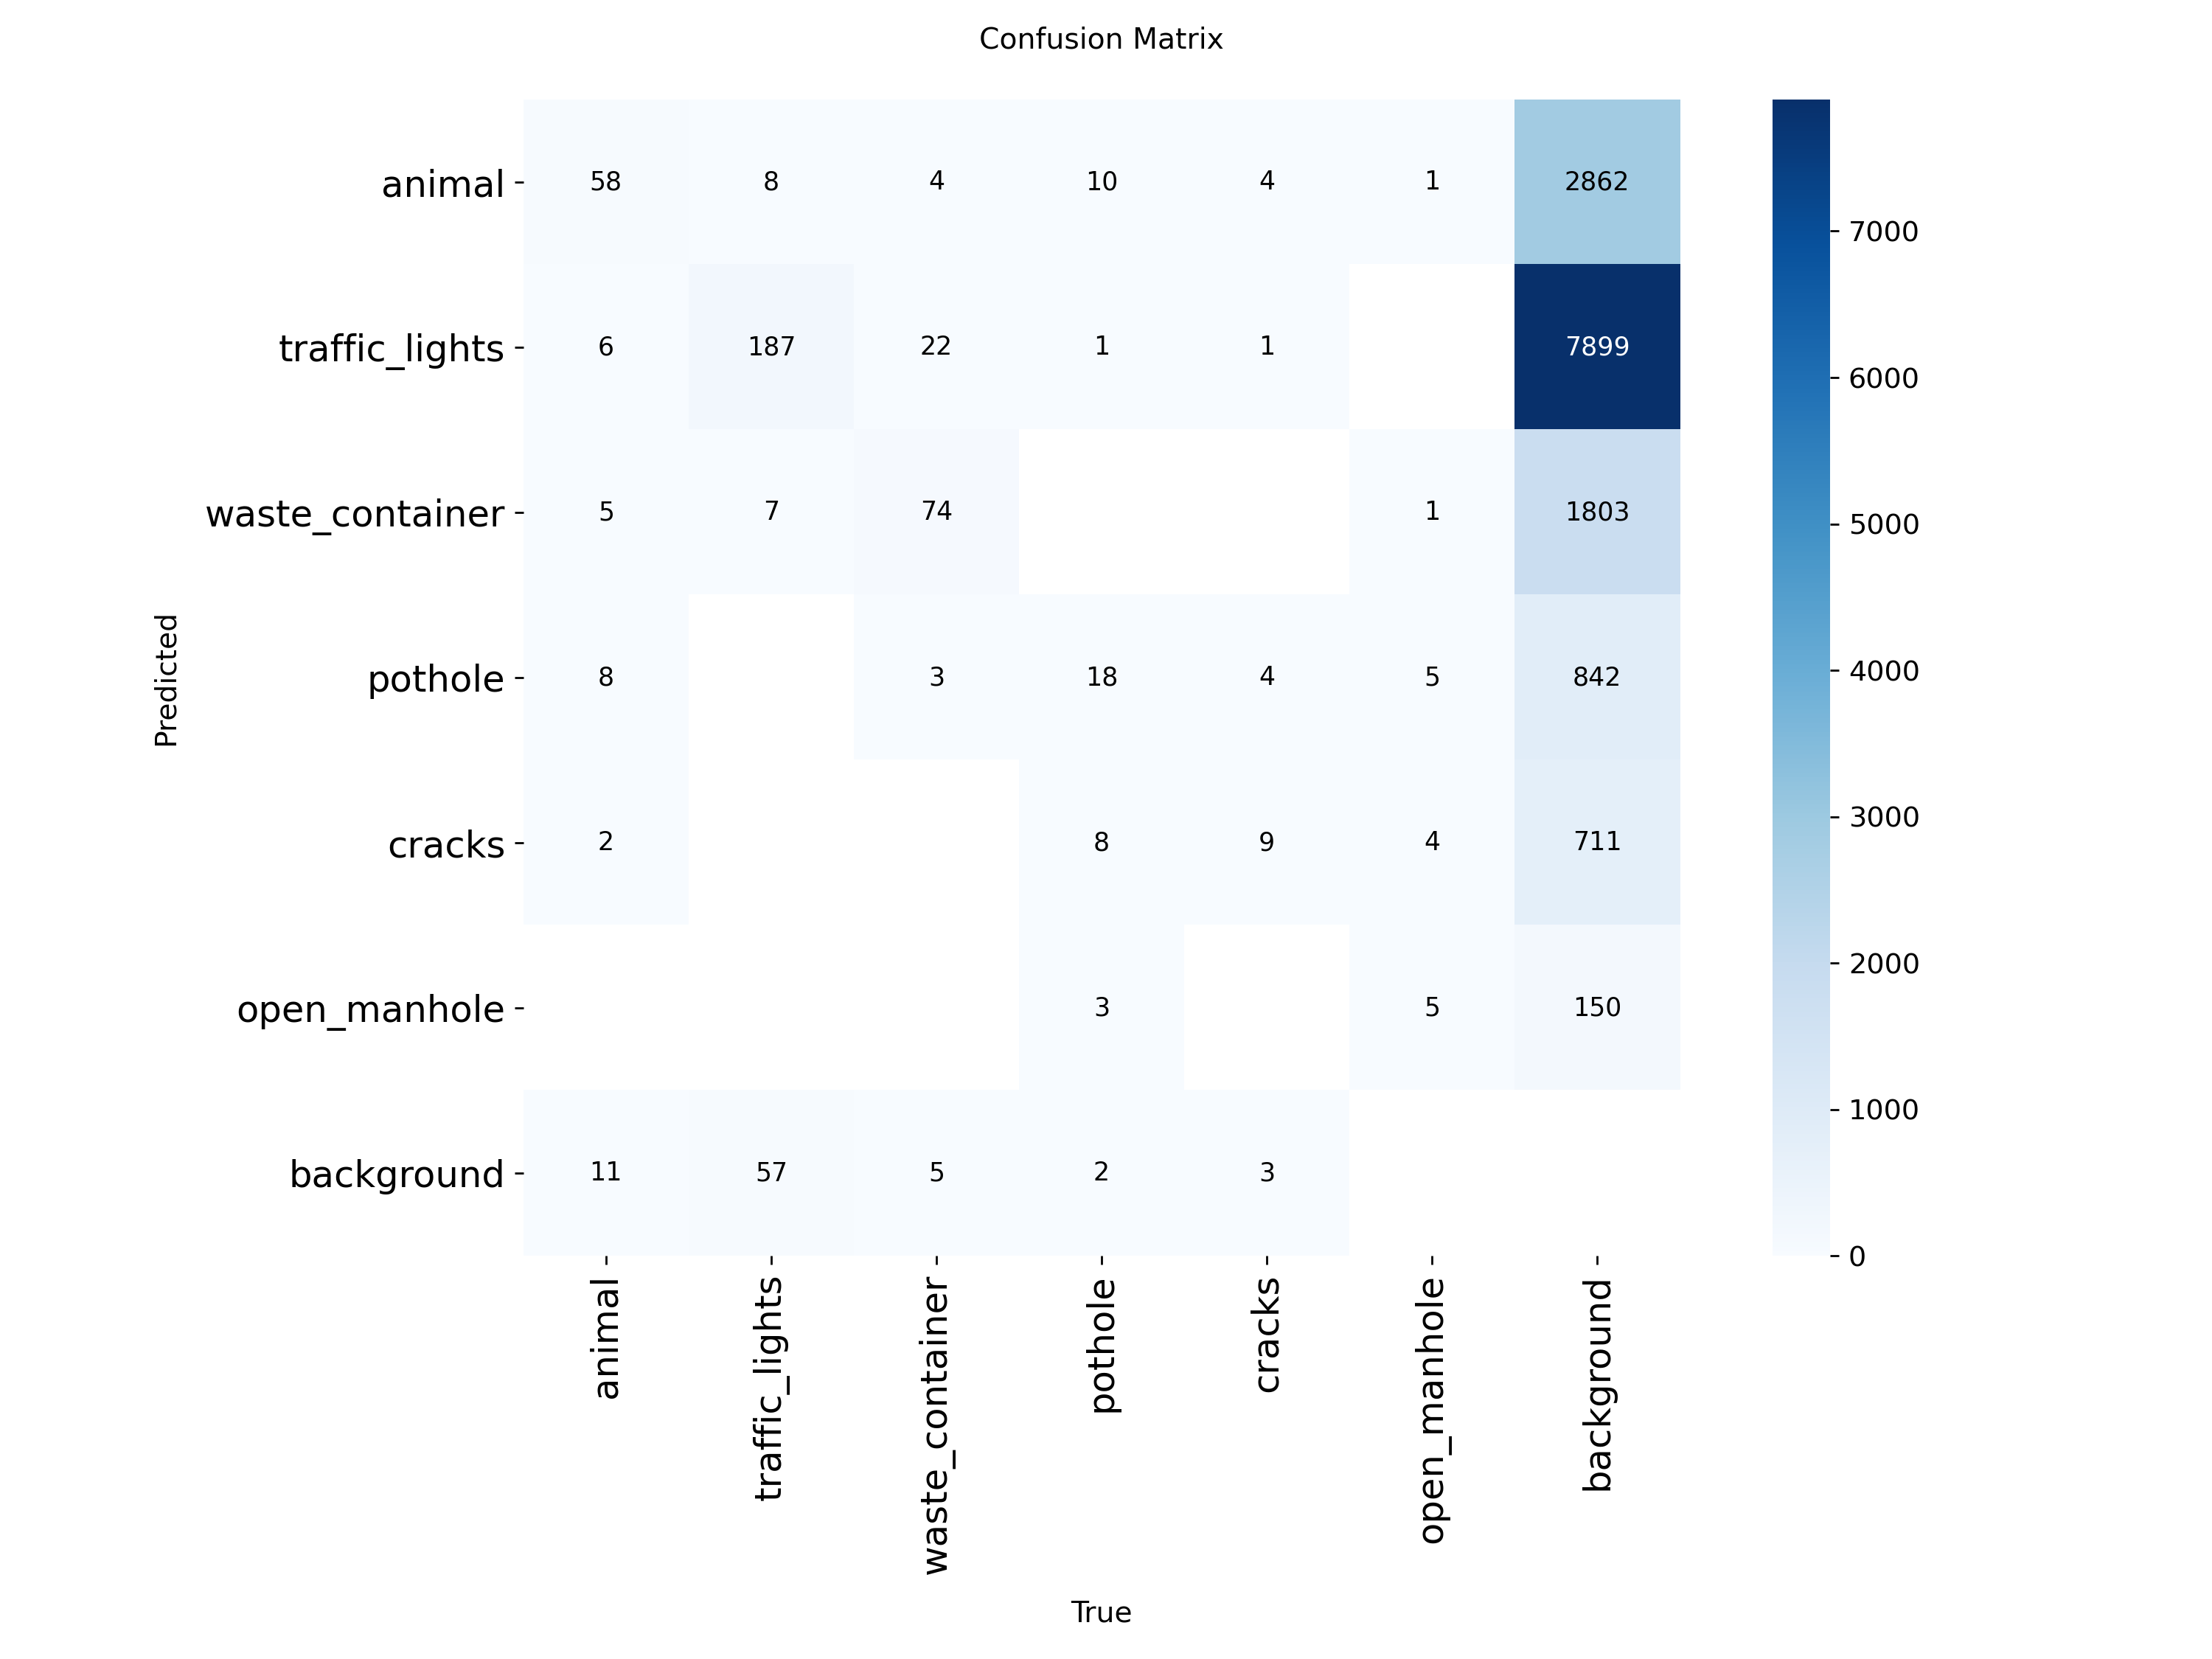


confusion_matrix_normalized.png


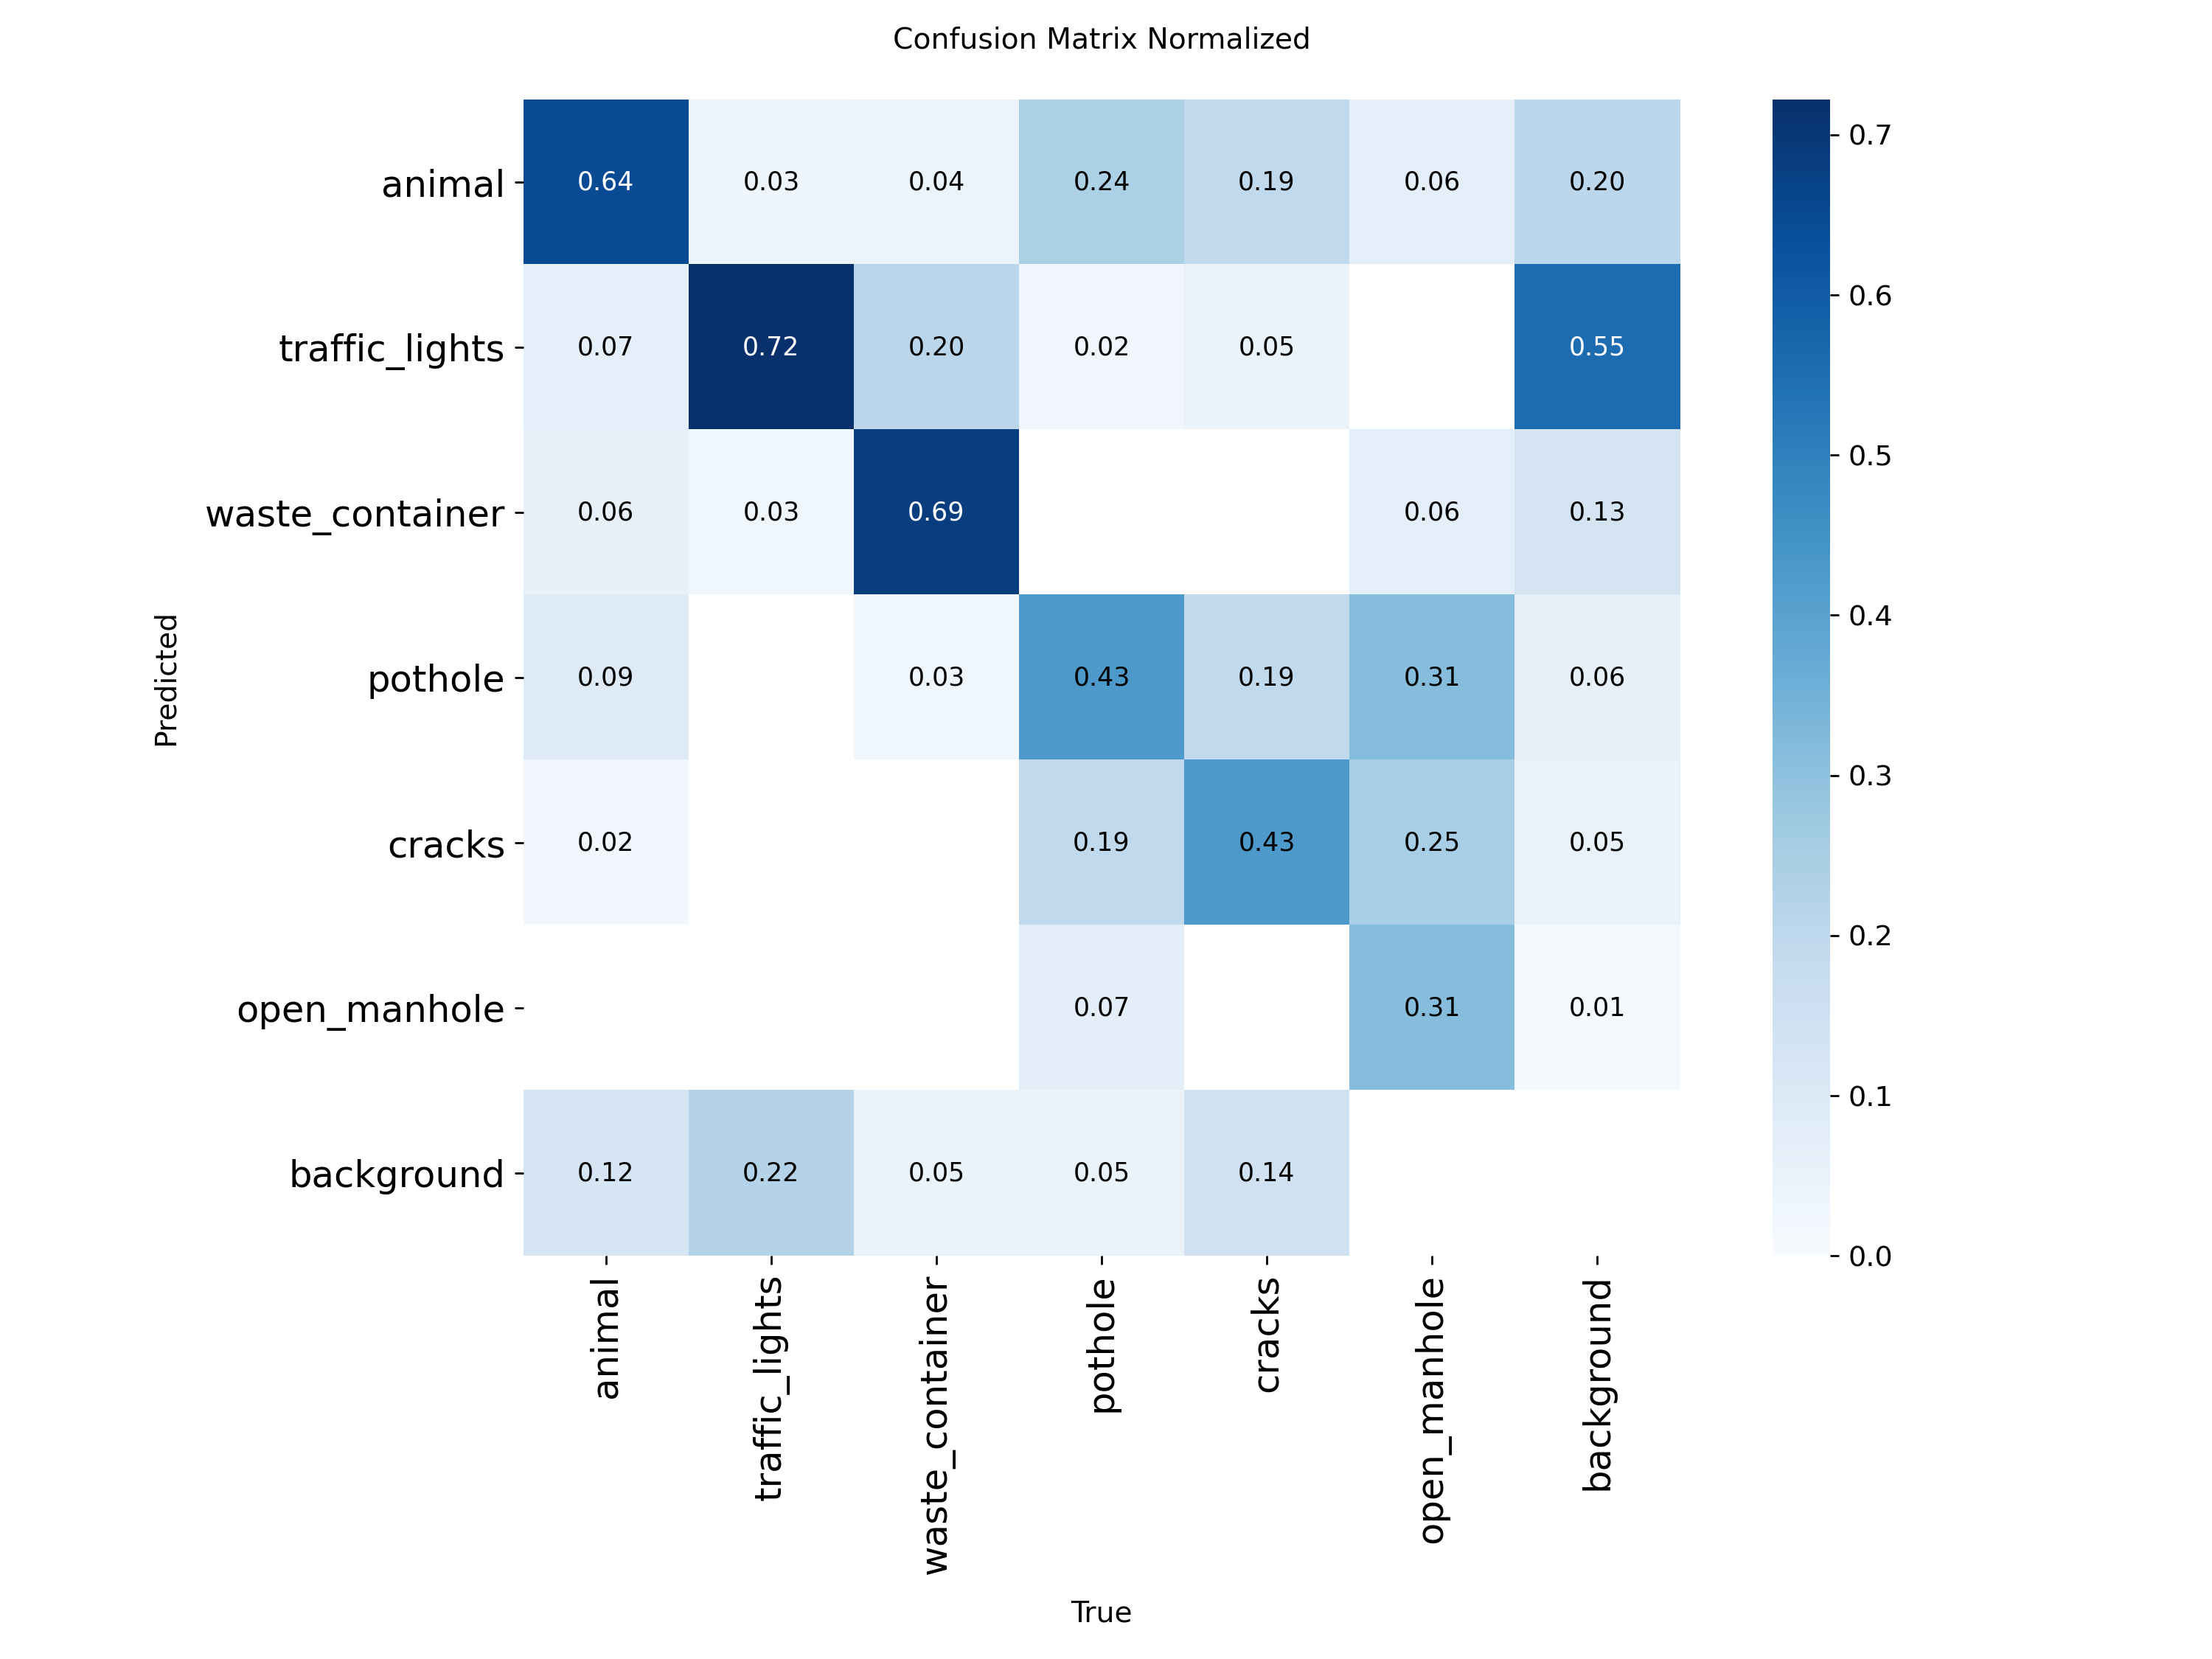

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pasta_treino = Path("/content/runs/auditoria/yolov8n")
pasta_teste = Path("/content/runs/auditoria/teste_final")
csv_path = pasta_treino / "results.csv"

if not csv_path.exists():
    raise FileNotFoundError(
        f"Não encontrei {csv_path}. Execute a célula de treinamento antes desta análise."
    )

df_resultados = pd.read_csv(csv_path)
df_resultados.columns = [col.strip() for col in df_resultados.columns]

# Identifica as colunas de perda disponíveis.
colunas_perda = [
    col for col in df_resultados.columns
    if "loss" in col.lower()
]

print("Colunas de perda encontradas:", colunas_perda)

if colunas_perda:
    # Usa uma posição por linha do CSV, evitando incompatibilidade
    # entre o eixo X e as séries de perda.
    if "epoch" in df_resultados.columns:
        eixo_x = df_resultados["epoch"]
    else:
        eixo_x = range(1, len(df_resultados) + 1)

    plt.figure(figsize=(12, 6))

    for coluna in colunas_perda:
        plt.plot(
            eixo_x,
            df_resultados[coluna],
            marker=".",
            label=coluna
        )

    plt.title("Perdas durante o treinamento e a validação")
    plt.xlabel("Época")
    plt.ylabel("Valor da perda")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    arquivo_perdas = pasta_treino / "curvas_perda.png"
    plt.savefig(arquivo_perdas, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Gráfico salvo em: {arquivo_perdas}")

    print("\nValores de perda na última época registrada:")
    colunas_exibir = (
        ["epoch"] + colunas_perda
        if "epoch" in df_resultados.columns
        else colunas_perda
    )
    display(df_resultados[colunas_exibir].tail(1))

else:
    print(
        "Não foram encontradas colunas de perda no results.csv. "
        "Confira as colunas disponíveis:"
    )
    print(df_resultados.columns.tolist())


# Apresenta a matriz de confusão e os gráficos de avaliação, se existirem.
arquivos_avaliacao = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
]

encontrados = []

for nome in arquivos_avaliacao:
    caminho = pasta_teste / nome

    if caminho.exists():
        encontrados.append(caminho)
        print(f"\n{nome}")
        display(Image(filename=str(caminho), width=700))

if not encontrados:
    print(
        "Nenhum gráfico de avaliação foi encontrado na pasta do teste. "
        "Confira se a célula de avaliação terminou com plots=True."
    )

### Resultados registrados na execução do projeto

Os resultados abaixo são os valores obtidos na execução usada para a entrega. Se o notebook for treinado novamente, os valores podem mudar ligeiramente conforme ambiente, versões e aleatoriedade.

| Métrica | Resultado |
|---|---:|
| Precision | 0,7412 |
| Recall | 0,6572 |
| mAP@50 | 0,6958 |
| mAP@50–95 | 0,3970 |

- **Precision:** proporção das detecções positivas que estavam corretas.
- **Recall:** proporção dos objetos anotados que o modelo conseguiu detectar.
- **mAP@50:** desempenho médio de detecção com IoU de 0,50.
- **mAP@50–95:** desempenho médio considerando limiares de IoU de 0,50 a 0,95.

As métricas devem ser interpretadas em relação a este dataset e às seis classes utilizadas; não representam uma certificação de acessibilidade ou de segurança de calçadas.

## 7. Exportação e empacotamento dos artefatos

A aplicação mobile utiliza o modelo ONNX com entrada de 640 × 640. Esta etapa copia o modelo PyTorch, o ONNX, a configuração de classes, as métricas de treinamento, as curvas de perda e os gráficos finais (incluindo a matriz de confusão, quando gerados) para uma pasta de entrega. Não é feita uma segunda exportação com tamanho diferente, evitando que arquivos ONNX de tamanhos distintos sejam confundidos.

In [13]:
from pathlib import Path
import shutil
import zipfile
from google.colab import files

modelo_path = Path("/content/runs/auditoria/yolov8n/weights/best.pt")
onnx_path = Path("/content/runs/auditoria/yolov8n/weights/best.onnx")
dataset_yaml = Path("/content/yolo_auditoria/data.yaml")
resultados_csv = Path("/content/runs/auditoria/yolov8n/results.csv")
pasta_teste = Path("/content/runs/auditoria/teste_final")

saida = Path("/content/entrega_auditoria")
saida.mkdir(parents=True, exist_ok=True)

for caminho in [modelo_path, onnx_path, dataset_yaml, resultados_csv]:
    if not caminho.exists():
        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {caminho}. "
            "Execute as etapas anteriores antes de empacotar."
        )

shutil.copy2(modelo_path, saida / "best.pt")
shutil.copy2(onnx_path, saida / "best_640.onnx")
shutil.copy2(resultados_csv, saida / "resultados_treinamento.csv")

# Criar um data.yaml portátil, sem caminho absoluto do Colab.
config_portatil = {
    "path": ".",
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "animal",
        1: "traffic_lights",
        2: "waste_container",
        3: "pothole",
        4: "cracks",
        5: "open_manhole",
    },
}
(saida / "data.yaml").write_text(
    yaml.safe_dump(config_portatil, sort_keys=False, allow_unicode=True),
    encoding="utf-8"
)

# Copiar gráficos de avaliação do conjunto de teste, quando disponíveis.
for nome in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
]:
    origem = pasta_teste / nome
    if origem.exists():
        shutil.copy2(origem, saida / nome)

# Copiar gráficos do treinamento e a curva de perdas criada na seção 6.1.
for nome in ["results.png", "curvas_perda.png"]:
    origem = modelo_path.parent.parent / nome
    if origem.exists():
        shutil.copy2(origem, saida / nome)

relatorio = """Projeto: Auditoria de Calçadas — experimento YOLOv8n

Fonte do dataset:
https://zenodo.org/records/18871460

Classes treinadas:
0 animal
1 traffic_lights
2 waste_container
3 pothole
4 cracks
5 open_manhole

A pasta good_road foi excluída porque seus arquivos de anotação estavam vazios.
Divisão registrada: 1.933 imagens de treino, 241 de validação e 244 de teste.
Treinamento: YOLOv8n pré-treinado, 15 épocas, imgsz=640, batch=16.

Métricas registradas no conjunto de teste:
Precision: 0.7412
Recall: 0.6572
mAP@50: 0.6958
mAP@50-95: 0.3970

Os gráficos de avaliação e a matriz de confusão são incluídos no pacote quando
gerados pelo Ultralytics. O arquivo resultados_treinamento.csv permite consultar
as perdas registradas por época; a curva_perda.png é criada pela seção 6.1.

"""
(saida / "relatorio.txt").write_text(relatorio, encoding="utf-8")

zip_path = Path("/content/entrega_auditoria.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as arquivo_zip:
    for arquivo in sorted(saida.rglob("*")):
        if arquivo.is_file():
            arquivo_zip.write(arquivo, arquivo.relative_to(saida))

print("Pacote criado:", zip_path)
print("Arquivos incluídos:")
for arquivo in sorted(saida.iterdir()):
    if arquivo.is_file():
        print(f"- {arquivo.name} ({arquivo.stat().st_size / 1024 / 1024:.2f} MB)")

files.download(str(zip_path))

Pacote criado: /content/entrega_auditoria.zip
Arquivos incluídos:
- best.pt (6.19 MB)
- best_640.onnx (12.19 MB)
- confusion_matrix.png (0.20 MB)
- confusion_matrix_normalized.png (0.23 MB)
- curvas_perda.png (0.11 MB)
- data.yaml (0.00 MB)
- relatorio.txt (0.00 MB)
- resultados_treinamento.csv (0.00 MB)
- results.png (0.29 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusão

O experimento demonstra um pipeline de visão computacional que parte de imagens rotuladas, prepara dados para detecção de objetos, treina um YOLOv8n, avalia o desempenho em um conjunto de teste e exporta o modelo para inferência em uma aplicação mobile.